# Britannia Road Network Analysis

This notebook runs a suite of structural and spatial tests on the **Britannia** province sub-network extracted from the cleaned, time-weighted Roman road graph (`province_subnetworks.pkl`).

| Section | What it tests |
|---|---|
| 1. Connectivity | Are all nodes reachable? How many components? |
| 2. Degree Distribution | How many junctions vs. dead-ends? |
| 3. Betweenness Centrality | Which nodes and roads are most critical bottlenecks? |
| 4. Shortest Paths | Travel times between major Roman sites |
| 5. Diameter & Eccentricity | What are the most peripheral and most central locations? |
| 6. Clustering Coefficient | How "loopy" is the local road structure? |

All maps use the same **CartoDB Positron** tile base and visual conventions as the main `itinere-X_network.ipynb` notebook.

In [1]:
from __future__ import annotations
import pickle
import numpy as np
import pandas as pd
import geopandas as gpd
import networkx as nx
import folium
import branca.colormap as bcm
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.cm as cm
import pyproj
from shapely.geometry import Point

# ── Load Britannia subgraph + edge GeoDataFrame ────────────────────────────────
with open("province_subnetworks.pkl", "rb") as f:
    subs = pickle.load(f)

G_brit   = subs["province_subgraphs"]["Britannia"]         # NetworkX Graph (EPSG:3395 node keys)
edges_4326 = subs["province_edge_tables"]["Britannia"]     # GeoDataFrame, already EPSG:4326

# ── Coordinate helpers ─────────────────────────────────────────────────────────
_trans_fwd  = pyproj.Transformer.from_crs("EPSG:3395", "EPSG:4326", always_xy=True)  # 3395→4326
_trans_inv  = pyproj.Transformer.from_crs("EPSG:4326", "EPSG:3395", always_xy=True)  # 4326→3395

def xy_to_latlon(x, y):
    """Convert a single EPSG:3395 point to (lat, lon)."""
    lon, lat = _trans_fwd.transform(x, y)
    return (lat, lon)

def geom_to_latlons(geom):
    """Convert a Shapely LineString (EPSG:3395) to a [[lat,lon],...] list for folium."""
    return [list(xy_to_latlon(x, y)) for x, y in geom.coords]

# Pre-compute (lat, lon) for every node
node_latlon = {n: xy_to_latlon(n[0], n[1]) for n in G_brit.nodes()}

# Map centre
_lats = [ll[0] for ll in node_latlon.values()]
_lons = [ll[1] for ll in node_latlon.values()]
MAP_CENTER = [np.mean(_lats), np.mean(_lons)]
MAP_ZOOM   = 7

# LCC (used by several sections below)
_comps = sorted(nx.connected_components(G_brit), key=len, reverse=True)
lcc_nodes = _comps[0]
G_lcc = G_brit.subgraph(lcc_nodes).copy()

print(f"Loaded Britannia: {G_brit.number_of_nodes()} nodes, {G_brit.number_of_edges()} edges")
print(f"LCC:              {G_lcc.number_of_nodes()} nodes, {G_lcc.number_of_edges()} edges")
print(f"Edge GDF:         {edges_4326.shape}")
print(f"Map centre:       {MAP_CENTER[0]:.3f}°N, {MAP_CENTER[1]:.3f}°E")

Loaded Britannia: 672 nodes, 935 edges
LCC:              672 nodes, 935 edges
Edge GDF:         (935, 8)
Map centre:       52.416°N, -1.192°E


---
## 1. Connectivity

Identifies all **connected components** in the Britannia subgraph. The largest connected component (LCC) forms the main network; smaller fragments are isolated road segments that cannot be reached from the main network.

**Map:** each component is rendered in a distinct colour. The main LCC is shown in the standard **road blue** (`#1f77b4`); isolated fragments are highlighted in contrasting colours so they are easy to spot.

In [2]:
# ── 1. Connectivity ────────────────────────────────────────────────────────────
comps_sorted = sorted(nx.connected_components(G_brit), key=len, reverse=True)
num_cc       = len(comps_sorted)
lcc_frac     = len(comps_sorted[0]) / G_brit.number_of_nodes()

print(f"Connected components : {num_cc}")
print(f"Largest CC           : {len(comps_sorted[0])} nodes ({lcc_frac:.1%} of total)")
print()
for i, c in enumerate(comps_sorted):
    edge_cnt = G_brit.subgraph(c).number_of_edges()
    print(f"  Component {i+1:2d}: {len(c):4d} nodes, {edge_cnt:4d} edges")

# Colour palette – first colour (main LCC) matches the standard road blue
COMP_COLORS = [
    "#1f77b4",  # main LCC – road blue
    "#d62728",  # fragment 2
    "#ff7f0e",  # fragment 3
    "#9467bd",  # fragment 4
    "#8c564b",  # fragment 5
    "#e377c2",  # fragment 6
    "#17becf",  # fragment 7+
]

node_comp_color = {}
for ci, comp in enumerate(comps_sorted):
    col = COMP_COLORS[min(ci, len(COMP_COLORS) - 1)]
    for n in comp:
        node_comp_color[n] = col

# ── Map ────────────────────────────────────────────────────────────────────────
m1 = folium.Map(location=MAP_CENTER, zoom_start=MAP_ZOOM, tiles="CartoDB positron")

fg_edges = folium.FeatureGroup(name="Roads (by component)", show=True)
for u, v, d in G_brit.edges(data=True):
    geom = d.get("geometry")
    if geom is None or geom.is_empty:
        continue
    col = node_comp_color.get(u, "#aaaaaa")
    folium.PolyLine(
        locations=geom_to_latlons(geom),
        color=col,
        weight=2.5,
        opacity=0.85,
        tooltip=f"edge_id={d.get('edge_id')}",
    ).add_to(fg_edges)
fg_edges.add_to(m1)

fg_nodes = folium.FeatureGroup(name="Nodes (by component)", show=True)
for n in G_brit.nodes():
    lat, lon = node_latlon[n]
    col       = node_comp_color.get(n, "#aaaaaa")
    in_lcc    = n in lcc_nodes
    folium.CircleMarker(
        location=[lat, lon],
        radius=3 if in_lcc else 6,
        color=col,
        fill=True, fill_color=col, fill_opacity=0.9,
        weight=1 if in_lcc else 2,
        tooltip=(
            f"node_id={G_brit.nodes[n].get('node_id')} | "
            f"comp_size={len([c for c in comps_sorted if n in c][0])} | "
            f"{'LCC' if in_lcc else 'ISOLATED'}"
        ),
    ).add_to(fg_nodes)
fg_nodes.add_to(m1)

folium.LayerControl(collapsed=False).add_to(m1)
m1

Connected components : 1
Largest CC           : 672 nodes (100.0% of total)

  Component  1:  672 nodes,  935 edges


---
## 2. Degree Distribution

The **degree** of a node is the number of road segments that meet at that intersection.

- **Degree 1** — dead-end / terminal nodes (road terminates here)
- **Degree 2** — pass-through nodes (after degree-2 simplification these are genuine branch points)
- **Degree ≥ 3** — true road junctions

**Map:** nodes are coloured on a **Yellow → Orange → Red** scale by degree; radius also scales with degree so high-junction hubs stand out visually.

Min degree   : 1
Max degree   : 7
Mean degree  : 2.78
Dead-ends (1): 159
Pass-thru (2): 0
Junctions (≥3): 513


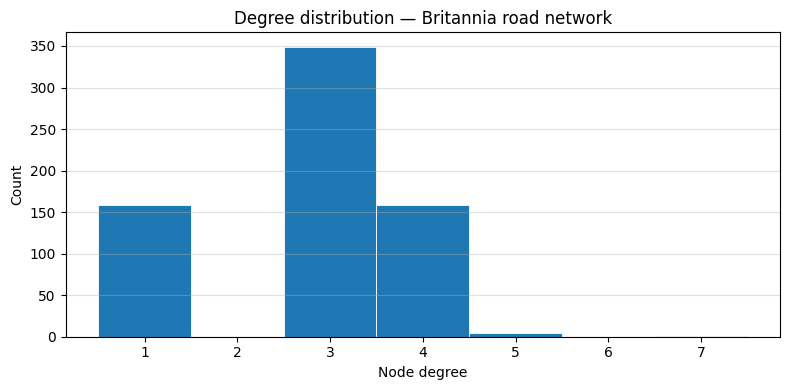

In [3]:
# ── 2. Degree Distribution ─────────────────────────────────────────────────────
degrees   = dict(G_brit.degree())
deg_vals  = np.array(list(degrees.values()))
max_deg   = int(deg_vals.max())

print(f"Min degree   : {deg_vals.min()}")
print(f"Max degree   : {max_deg}")
print(f"Mean degree  : {deg_vals.mean():.2f}")
print(f"Dead-ends (1): {(deg_vals == 1).sum()}")
print(f"Pass-thru (2): {(deg_vals == 2).sum()}")
print(f"Junctions (≥3): {(deg_vals >= 3).sum()}")

# ── Histogram ─────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 4))
bins = range(1, max_deg + 2)
ax.hist(deg_vals, bins=bins, align="left", color="#1f77b4", edgecolor="white", linewidth=0.6)
ax.set_xlabel("Node degree")
ax.set_ylabel("Count")
ax.set_title("Degree distribution — Britannia road network")
ax.set_xticks(range(1, max_deg + 1))
ax.grid(axis="y", alpha=0.4)
plt.tight_layout()
plt.show()

# ── Map ───────────────────────────────────────────────────────────────────────
cmap_deg  = cm.YlOrRd
norm_deg  = mcolors.Normalize(vmin=1, vmax=max_deg)

def deg_color(d):
    return mcolors.to_hex(cmap_deg(norm_deg(d))[:3])

m2 = folium.Map(location=MAP_CENTER, zoom_start=MAP_ZOOM, tiles="CartoDB positron")

fg_roads = folium.FeatureGroup(name="Roads", show=True)
folium.GeoJson(
    edges_4326.__geo_interface__,
    style_function=lambda feat: {"color": "#1f77b4", "weight": 2.0, "opacity": 0.55},
    tooltip=folium.GeoJsonTooltip(
        fields=["edge_id", "dist_m", "time_s"],
        aliases=["edge_id", "dist (m)", "time (s)"],
        sticky=True,
    ),
).add_to(fg_roads)
fg_roads.add_to(m2)

fg_nodes = folium.FeatureGroup(name="Nodes (degree)", show=True)
for n, d in sorted(degrees.items(), key=lambda x: x[1]):   # draw low-degree first so hubs are on top
    lat, lon = node_latlon[n]
    folium.CircleMarker(
        location=[lat, lon],
        radius=2 + d,
        color=deg_color(d),
        fill=True, fill_color=deg_color(d), fill_opacity=0.9,
        weight=0.5,
        tooltip=f"node_id={G_brit.nodes[n].get('node_id')} | degree={d}",
    ).add_to(fg_nodes)
fg_nodes.add_to(m2)

# Branca colour scale legend
cm_legend = bcm.LinearColormap(
    [mcolors.to_hex(cmap_deg(norm_deg(v))[:3]) for v in range(1, max_deg + 1)],
    vmin=1, vmax=max_deg,
    caption="Node degree",
)
cm_legend.add_to(m2)
folium.LayerControl(collapsed=False).add_to(m2)
m2

---
## 3. Betweenness Centrality

**Betweenness centrality** measures how often a node (or edge) lies on the shortest path between all other pairs of nodes. High-betweenness nodes are **critical bottlenecks** — removing them would most disrupt the network.

Computed on the **LCC** only using travel-time weights. Both **node** and **edge** betweenness are shown.

**Map:**
- Edges are coloured **Yellow → Red** by edge betweenness and scaled in width
- Nodes are coloured on a **Plasma** scale by node betweenness and sized proportionally

In [4]:
# ── 3. Betweenness Centrality ──────────────────────────────────────────────────
print(f"Computing betweenness centrality on LCC ({G_lcc.number_of_nodes()} nodes) …")
bc  = nx.betweenness_centrality(G_lcc, weight="weight", normalized=True)
ebc = nx.edge_betweenness_centrality(G_lcc, weight="weight", normalized=True)
print("Done.")

bc_vals  = np.array(list(bc.values()))
ebc_vals = np.array(list(ebc.values()))

print(f"Node BC  — max: {bc_vals.max():.4f}, mean: {bc_vals.mean():.4f}")
print(f"Edge BC  — max: {ebc_vals.max():.4f}, mean: {ebc_vals.mean():.4f}")
print()
print("Top 10 nodes by betweenness centrality:")
for n, bv in sorted(bc.items(), key=lambda x: x[1], reverse=True)[:10]:
    lat, lon = node_latlon[n]
    print(f"  node_id={G_brit.nodes[n].get('node_id'):5d}  BC={bv:.4f}  @ ({lat:.3f}°N, {lon:.3f}°E)")

# ── Colour helpers ─────────────────────────────────────────────────────────────
cmap_nbc  = cm.plasma
norm_nbc  = mcolors.Normalize(vmin=0, vmax=np.percentile(bc_vals, 99))

cmap_ebc  = cm.YlOrRd
norm_ebc  = mcolors.Normalize(vmin=0, vmax=np.percentile(ebc_vals, 99))

def nbc_color(v):
    return mcolors.to_hex(cmap_nbc(norm_nbc(v))[:3])

def ebc_color(v):
    return mcolors.to_hex(cmap_ebc(norm_ebc(v))[:3])

# ── Map ───────────────────────────────────────────────────────────────────────
m3 = folium.Map(location=MAP_CENTER, zoom_start=MAP_ZOOM, tiles="CartoDB positron")

# Edges coloured + weighted by edge betweenness
fg_edges = folium.FeatureGroup(name="Roads (edge betweenness)", show=True)
for u, v, d in G_lcc.edges(data=True):
    geom = d.get("geometry")
    if geom is None or geom.is_empty:
        continue
    ev  = ebc.get((u, v), ebc.get((v, u), 0.0))
    col = ebc_color(ev)
    wt  = 1.5 + 6.0 * float(norm_ebc(ev))
    folium.PolyLine(
        locations=geom_to_latlons(geom),
        color=col,
        weight=wt,
        opacity=0.85,
        tooltip=f"edge_id={d.get('edge_id')} | edge_BC={ev:.5f}",
    ).add_to(fg_edges)
fg_edges.add_to(m3)

# Nodes coloured by node betweenness (drawn after edges so they appear on top)
fg_nodes = folium.FeatureGroup(name="Nodes (node betweenness)", show=True)
for n, bv in sorted(bc.items(), key=lambda x: x[1]):   # low BC first so high-BC rendered on top
    lat, lon = node_latlon[n]
    r = 3.0 + 13.0 * float(norm_nbc(bv))
    folium.CircleMarker(
        location=[lat, lon],
        radius=r,
        color="#333333",
        fill=True, fill_color=nbc_color(bv), fill_opacity=0.9,
        weight=0.4,
        tooltip=f"node_id={G_brit.nodes[n].get('node_id')} | BC={bv:.5f}",
    ).add_to(fg_nodes)
fg_nodes.add_to(m3)

# Legend for node BC
n_steps = 6
step_vals = np.linspace(0, np.percentile(bc_vals, 99), n_steps)
nbc_legend = bcm.LinearColormap(
    [mcolors.to_hex(cmap_nbc(norm_nbc(v))[:3]) for v in step_vals],
    vmin=0, vmax=float(np.percentile(bc_vals, 99)),
    caption="Node betweenness centrality (normalised)",
)
nbc_legend.add_to(m3)
folium.LayerControl(collapsed=False).add_to(m3)
m3

Computing betweenness centrality on LCC (672 nodes) …
Done.
Node BC  — max: 0.1946, mean: 0.0300
Edge BC  — max: 0.1867, mean: 0.0225

Top 10 nodes by betweenness centrality:
  node_id= 1703  BC=0.1946  @ (53.235°N, -0.537°E)
  node_id= 1290  BC=0.1923  @ (52.653°N, -1.843°E)
  node_id= 1697  BC=0.1874  @ (53.214°N, -0.545°E)
  node_id= 1262  BC=0.1696  @ (51.714°N, -1.964°E)
  node_id= 1700  BC=0.1655  @ (53.285°N, -0.539°E)
  node_id= 1645  BC=0.1566  @ (51.981°N, -0.671°E)
  node_id= 1641  BC=0.1524  @ (51.987°N, -0.689°E)
  node_id= 1784  BC=0.1505  @ (52.588°N, -0.356°E)
  node_id= 1268  BC=0.1505  @ (51.725°N, -1.942°E)
  node_id= 1644  BC=0.1499  @ (51.981°N, -0.671°E)


---
## 4. Shortest Paths between Roman Sites

Computes **Dijkstra shortest paths** (minimising travel time in seconds) between six major Roman settlements in Britannia. Each route is drawn on the map in a distinct colour over the faded base network.

| Site | Modern location |
|---|---|
| Londinium | London |
| Eboracum | York |
| Camulodunum | Colchester |
| Aquae Sulis | Bath |
| Isca Dumnoniorum | Exeter |
| Viroconium | Wroxeter |

Nearest network nodes are found by minimum Euclidean distance in EPSG:3395.

In [5]:
# ── 4. Shortest Paths ─────────────────────────────────────────────────────────
def nearest_node(G, lon_4326, lat_4326):
    """Return the G node (EPSG:3395 key) nearest to a (lon, lat) in EPSG:4326."""
    sx, sy = _trans_inv.transform(lon_4326, lat_4326)
    arr    = np.array(list(G.nodes()))
    dists  = np.hypot(arr[:, 0] - sx, arr[:, 1] - sy)
    return tuple(arr[np.argmin(dists)])

# Known Roman sites in Britannia (lon, lat EPSG:4326)
SITES = {
    "Londinium":        (-0.09,  51.51),
    "Eboracum":         (-1.08,  53.96),
    "Camulodunum":      ( 0.90,  51.89),
    "Aquae Sulis":      (-2.36,  51.38),
    "Isca Dumnoniorum": (-3.53,  50.72),
    "Viroconium":       (-2.66,  52.68),
}

site_nodes = {name: nearest_node(G_lcc, lon, lat) for name, (lon, lat) in SITES.items()}

print("Nearest LCC nodes to Roman sites:")
for name, node in site_nodes.items():
    lat, lon = node_latlon[node]
    print(f"  {name:<22s}: node_id={G_brit.nodes[node].get('node_id'):5d} @ ({lat:.3f}°N, {lon:.3f}°E)")

# Route pairs to compute
ROUTE_PAIRS  = [
    ("Londinium",   "Eboracum"),
    ("Londinium",   "Camulodunum"),
    ("Londinium",   "Aquae Sulis"),
    ("Londinium",   "Isca Dumnoniorum"),
    ("Londinium",   "Viroconium"),
    ("Aquae Sulis", "Eboracum"),
]
ROUTE_COLORS = ["#d62728", "#ff7f0e", "#2ca02c", "#9467bd", "#8c564b", "#17becf"]

print()
print("Shortest-path travel times (at 2 km/h walking speed):")
routes = {}
for (src, dst), col in zip(ROUTE_PAIRS, ROUTE_COLORS):
    try:
        path   = nx.shortest_path(G_lcc, site_nodes[src], site_nodes[dst], weight="weight")
        t_secs = nx.shortest_path_length(G_lcc, site_nodes[src], site_nodes[dst], weight="weight")
        routes[(src, dst)] = {"path": path, "time_s": t_secs, "color": col}
        print(f"  {src:<22s} → {dst:<22s}: {t_secs/3600:6.1f} h  ({len(path)} nodes)")
    except nx.NetworkXNoPath:
        print(f"  {src} → {dst}: NO PATH")

# ── Map ───────────────────────────────────────────────────────────────────────
m4 = folium.Map(location=MAP_CENTER, zoom_start=MAP_ZOOM, tiles="CartoDB positron")

# Faded base network
fg_base = folium.FeatureGroup(name="All roads (base)", show=True)
folium.GeoJson(
    edges_4326.__geo_interface__,
    style_function=lambda feat: {"color": "#1f77b4", "weight": 1.5, "opacity": 0.35},
).add_to(fg_base)
fg_base.add_to(m4)

# One FeatureGroup per route
for (src, dst), info in routes.items():
    path = info["path"]
    col  = info["color"]
    label = f"{src} → {dst}  ({info['time_s']/3600:.1f} h)"
    fg_route = folium.FeatureGroup(name=label, show=True)
    for i in range(len(path) - 1):
        u, v = path[i], path[i + 1]
        d = G_lcc[u][v]
        geom = d.get("geometry")
        if geom is not None and not geom.is_empty:
            folium.PolyLine(
                locations=geom_to_latlons(geom),
                color=col,
                weight=5,
                opacity=0.92,
                tooltip=label,
            ).add_to(fg_route)
    fg_route.add_to(m4)

# Site markers
fg_sites = folium.FeatureGroup(name="Roman sites", show=True)
for name, node in site_nodes.items():
    lat, lon = node_latlon[node]
    folium.CircleMarker(
        location=[lat, lon],
        radius=8,
        color="#ffffff",
        fill=True, fill_color="#d62728", fill_opacity=1.0,
        weight=2,
        tooltip=name,
    ).add_to(fg_sites)
    folium.Marker(
        location=[lat + 0.15, lon],
        icon=folium.DivIcon(
            html=f'<div style="font-size:10px;font-weight:bold;color:#333333;white-space:nowrap;'
                 f'background:rgba(255,255,255,0.75);padding:1px 3px;border-radius:2px;">'
                 f'{name}</div>',
            icon_size=(130, 20),
            icon_anchor=(65, 20),
        ),
    ).add_to(fg_sites)
fg_sites.add_to(m4)

folium.LayerControl(collapsed=False).add_to(m4)
m4

Nearest LCC nodes to Roman sites:
  Londinium             : node_id= 1881 @ (51.513°N, -0.087°E)
  Eboracum              : node_id= 1534 @ (53.960°N, -1.078°E)
  Camulodunum           : node_id= 2115 @ (51.890°N, 0.902°E)
  Aquae Sulis           : node_id= 1179 @ (51.381°N, -2.359°E)
  Isca Dumnoniorum      : node_id=  894 @ (50.720°N, -3.529°E)
  Viroconium            : node_id= 1107 @ (52.670°N, -2.646°E)

Shortest-path travel times (at 2 km/h walking speed):
  Londinium              → Eboracum              :  252.7 h  (39 nodes)
  Londinium              → Camulodunum           :   66.6 h  (7 nodes)
  Londinium              → Aquae Sulis           :  133.1 h  (15 nodes)
  Londinium              → Isca Dumnoniorum      :  223.0 h  (22 nodes)
  Londinium              → Viroconium            :  194.8 h  (27 nodes)
  Aquae Sulis            → Eboracum              :  279.3 h  (24 nodes)


---
## 5. Network Diameter & Eccentricity

The **eccentricity** of a node is the maximum shortest-path distance from that node to any other node in the LCC (in travel-time seconds).

- **Diameter** — the maximum eccentricity (longest of all shortest paths)
- **Radius** — the minimum eccentricity
- **Center** — nodes whose eccentricity equals the radius (most central)
- **Periphery** — nodes whose eccentricity equals the diameter (most remote)

**Map:**
- Nodes are coloured **Green → Red** (central → peripheral) by eccentricity
- The exemplar diameter path (between two peripheral nodes) is highlighted in **orange**
- Centre and periphery nodes are marked with larger symbols

In [6]:
# ── 5. Network Diameter & Eccentricity ────────────────────────────────────────
print("Computing eccentricity on LCC (may take a moment) …")
ecc = nx.eccentricity(G_lcc, weight="weight")
print("Done.")

ecc_vals = np.array(list(ecc.values()))
diam = nx.diameter(G_lcc, e=ecc)
rad  = nx.radius(G_lcc, e=ecc)
center_nodes   = list(nx.center(G_lcc, e=ecc))
periphery_nodes = list(nx.periphery(G_lcc, e=ecc))

print(f"Diameter   : {diam/3600:.1f} h  ({diam:.0f} s)")
print(f"Radius     : {rad/3600:.1f} h  ({rad:.0f} s)")
print(f"Center nodes   : {len(center_nodes)}")
print(f"Periphery nodes: {len(periphery_nodes)}")

# Find the exemplar diameter path: pick one periphery node, trace to its farthest point
best_len, diam_path, diam_ends = 0, None, None
for pn in periphery_nodes[:5]:   # cap at 5 to keep runtime short
    lengths, paths = nx.single_source_dijkstra(G_lcc, pn, weight="weight")
    farthest = max(lengths, key=lengths.get)
    if lengths[farthest] > best_len:
        best_len  = lengths[farthest]
        diam_path = paths[farthest]
        diam_ends = (pn, farthest)

lat0, lon0 = node_latlon[diam_ends[0]]
lat1, lon1 = node_latlon[diam_ends[1]]
print(f"\nDiameter path: {len(diam_path)} nodes, {best_len/3600:.1f} h")
print(f"  From: ({lat0:.3f}°N, {lon0:.3f}°E)")
print(f"  To  : ({lat1:.3f}°N, {lon1:.3f}°E)")

# ── Colour helpers ─────────────────────────────────────────────────────────────
cmap_ecc = cm.RdYlGn_r   # green=central/low ecc, red=peripheral/high ecc
norm_ecc = mcolors.Normalize(vmin=ecc_vals.min(), vmax=ecc_vals.max())

def ecc_color(v):
    return mcolors.to_hex(cmap_ecc(norm_ecc(v))[:3])

# ── Map ───────────────────────────────────────────────────────────────────────
m5 = folium.Map(location=MAP_CENTER, zoom_start=MAP_ZOOM, tiles="CartoDB positron")

fg_base = folium.FeatureGroup(name="All roads (base)", show=True)
folium.GeoJson(
    edges_4326.__geo_interface__,
    style_function=lambda feat: {"color": "#1f77b4", "weight": 1.5, "opacity": 0.35},
).add_to(fg_base)
fg_base.add_to(m5)

# Diameter path
fg_diam = folium.FeatureGroup(
    name=f"Diameter path ({best_len/3600:.1f} h)", show=True
)
for i in range(len(diam_path) - 1):
    u, v = diam_path[i], diam_path[i + 1]
    geom = G_lcc[u][v].get("geometry")
    if geom is not None and not geom.is_empty:
        folium.PolyLine(
            locations=geom_to_latlons(geom),
            color="#ff7f0e",
            weight=5,
            opacity=0.95,
            tooltip=f"Diameter path | {best_len/3600:.1f} h",
        ).add_to(fg_diam)
fg_diam.add_to(m5)

# Nodes coloured by eccentricity
fg_nodes = folium.FeatureGroup(name="Nodes (eccentricity)", show=True)
for n, ev in ecc.items():
    lat, lon = node_latlon[n]
    folium.CircleMarker(
        location=[lat, lon],
        radius=4,
        color=ecc_color(ev),
        fill=True, fill_color=ecc_color(ev), fill_opacity=0.85,
        weight=0.5,
        tooltip=f"node_id={G_brit.nodes[n].get('node_id')} | ecc={ev/3600:.1f} h",
    ).add_to(fg_nodes)
fg_nodes.add_to(m5)

# Centre nodes
fg_center = folium.FeatureGroup(name="Network centre nodes", show=True)
for n in center_nodes:
    lat, lon = node_latlon[n]
    folium.CircleMarker(
        location=[lat, lon],
        radius=9,
        color="#ffffff",
        fill=True, fill_color="#2ca02c", fill_opacity=1.0,
        weight=2,
        tooltip=f"CENTRE | node_id={G_brit.nodes[n].get('node_id')} | ecc={ecc[n]/3600:.1f} h",
    ).add_to(fg_center)
fg_center.add_to(m5)

# Periphery nodes
fg_peri = folium.FeatureGroup(name="Periphery nodes", show=True)
for n in periphery_nodes:
    lat, lon = node_latlon[n]
    folium.CircleMarker(
        location=[lat, lon],
        radius=8,
        color="#ffffff",
        fill=True, fill_color="#d62728", fill_opacity=1.0,
        weight=2,
        tooltip=f"PERIPHERY | node_id={G_brit.nodes[n].get('node_id')} | ecc={ecc[n]/3600:.1f} h",
    ).add_to(fg_peri)
fg_peri.add_to(m5)

# Diameter endpoints (larger)
fg_ends = folium.FeatureGroup(name="Diameter endpoints", show=True)
for n, label in [(diam_ends[0], "Diameter start"), (diam_ends[1], "Diameter end")]:
    lat, lon = node_latlon[n]
    folium.CircleMarker(
        location=[lat, lon],
        radius=11,
        color="#ff7f0e",
        fill=True, fill_color="#ff7f0e", fill_opacity=1.0,
        weight=3,
        tooltip=f"{label} | node_id={G_brit.nodes[n].get('node_id')}",
    ).add_to(fg_ends)
fg_ends.add_to(m5)

# Legend
ecc_steps = np.linspace(ecc_vals.min(), ecc_vals.max(), 6)
ecc_legend = bcm.LinearColormap(
    [mcolors.to_hex(cmap_ecc(norm_ecc(v))[:3]) for v in ecc_steps],
    vmin=float(ecc_vals.min() / 3600),
    vmax=float(ecc_vals.max() / 3600),
    caption="Eccentricity (hours)",
)
ecc_legend.add_to(m5)
folium.LayerControl(collapsed=False).add_to(m5)
m5

Computing eccentricity on LCC (may take a moment) …
Done.
Diameter   : 681.3 h  (2452816 s)
Radius     : 353.6 h  (1272827 s)
Center nodes   : 1
Periphery nodes: 1

Diameter path: 44 nodes, 681.3 h
  From: (55.977°N, -3.294°E)
  To  : (50.635°N, -4.353°E)


---
## 6. Clustering Coefficient

The **local clustering coefficient** of a node measures the fraction of its neighbours that are also connected to each other — i.e. how many triangles exist around the node relative to how many could exist.

Road networks tend to have **very low** clustering coefficients (few triangles), but nodes near towns or road loops will show elevated values.

**Map:** nodes are coloured on a **Viridis** scale from low (dark purple = tree-like) to high (yellow = loopy). A bar chart shows the distribution.

Average clustering coefficient : 0.10762
Nodes with CC = 0 (no triangles): 433 (64.4%)
Nodes with CC > 0              : 239
Nodes with CC = 1 (full clique): 0

Top 10 nodes by clustering coefficient:
  node_id=  943  CC=0.6667  deg=3  @ (51.937°N, -3.343°E)
  node_id= 1002  CC=0.6667  deg=3  @ (50.728°N, -3.044°E)
  node_id= 1269  CC=0.6667  deg=3  @ (51.725°N, -1.942°E)
  node_id= 1541  CC=0.6667  deg=3  @ (51.988°N, -1.067°E)
  node_id= 1377  CC=0.6667  deg=3  @ (52.931°N, -1.476°E)
  node_id= 1657  CC=0.6667  deg=3  @ (52.227°N, -0.636°E)
  node_id=  941  CC=0.6667  deg=3  @ (51.937°N, -3.343°E)
  node_id= 1920  CC=0.6667  deg=3  @ (51.898°N, 0.021°E)
  node_id= 1187  CC=0.6667  deg=3  @ (51.405°N, -2.315°E)
  node_id= 1208  CC=0.6667  deg=3  @ (51.659°N, -2.189°E)


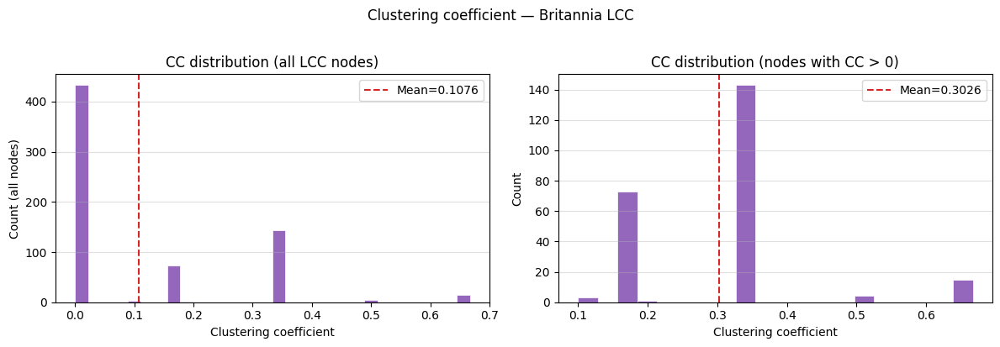

In [7]:
# ── 6. Clustering Coefficient ──────────────────────────────────────────────────
cc_all = nx.clustering(G_lcc)           # keyed on LCC nodes
avg_cc = nx.average_clustering(G_lcc)
cc_vals = np.array(list(cc_all.values()))

print(f"Average clustering coefficient : {avg_cc:.5f}")
print(f"Nodes with CC = 0 (no triangles): {(cc_vals == 0).sum()} ({(cc_vals == 0).mean():.1%})")
print(f"Nodes with CC > 0              : {(cc_vals > 0).sum()}")
print(f"Nodes with CC = 1 (full clique): {(cc_vals == 1).sum()}")
print()
print("Top 10 nodes by clustering coefficient:")
for n, cv in sorted(cc_all.items(), key=lambda x: x[1], reverse=True)[:10]:
    lat, lon = node_latlon[n]
    deg = G_lcc.degree(n)
    print(f"  node_id={G_brit.nodes[n].get('node_id'):5d}  CC={cv:.4f}  deg={deg}  @ ({lat:.3f}°N, {lon:.3f}°E)")

# ── Histogram ─────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# All nodes (most have CC=0)
axes[0].hist(cc_vals, bins=30, color="#9467bd", edgecolor="white", linewidth=0.5)
axes[0].axvline(avg_cc, color="#d62728", linestyle="--", linewidth=1.5, label=f"Mean={avg_cc:.4f}")
axes[0].set_xlabel("Clustering coefficient")
axes[0].set_ylabel("Count (all nodes)")
axes[0].set_title("CC distribution (all LCC nodes)")
axes[0].legend()
axes[0].grid(axis="y", alpha=0.4)

# Only nodes with CC > 0
cc_nonzero = cc_vals[cc_vals > 0]
if len(cc_nonzero) > 0:
    axes[1].hist(cc_nonzero, bins=20, color="#9467bd", edgecolor="white", linewidth=0.5)
    axes[1].axvline(cc_nonzero.mean(), color="#d62728", linestyle="--", linewidth=1.5,
                    label=f"Mean={cc_nonzero.mean():.4f}")
    axes[1].set_xlabel("Clustering coefficient")
    axes[1].set_ylabel("Count")
    axes[1].set_title("CC distribution (nodes with CC > 0)")
    axes[1].legend()
    axes[1].grid(axis="y", alpha=0.4)
else:
    axes[1].text(0.5, 0.5, "No nodes with CC > 0", ha="center", va="center", transform=axes[1].transAxes)

plt.suptitle("Clustering coefficient — Britannia LCC", y=1.02)
plt.tight_layout()
plt.show()

# ── Map ───────────────────────────────────────────────────────────────────────
cmap_cc = cm.viridis
norm_cc = mcolors.Normalize(vmin=0, vmax=1)

def cc_color(v):
    return mcolors.to_hex(cmap_cc(norm_cc(v))[:3])

m6 = folium.Map(location=MAP_CENTER, zoom_start=MAP_ZOOM, tiles="CartoDB positron")

fg_roads = folium.FeatureGroup(name="Roads", show=True)
folium.GeoJson(
    edges_4326.__geo_interface__,
    style_function=lambda feat: {"color": "#aaaaaa", "weight": 1.5, "opacity": 0.45},
).add_to(fg_roads)
fg_roads.add_to(m6)

# Draw nodes with CC=0 first (smaller, faded) then CC>0 on top
fg_zero = folium.FeatureGroup(name="Nodes CC=0 (no local loops)", show=True)
fg_nonz = folium.FeatureGroup(name="Nodes CC>0 (local loops)", show=True)
for n, cv in cc_all.items():
    lat, lon = node_latlon[n]
    col = cc_color(cv)
    if cv == 0:
        folium.CircleMarker(
            location=[lat, lon],
            radius=3,
            color=col,
            fill=True, fill_color=col, fill_opacity=0.7,
            weight=0.3,
            tooltip=f"node_id={G_brit.nodes[n].get('node_id')} | CC=0 | deg={G_lcc.degree(n)}",
        ).add_to(fg_zero)
    else:
        folium.CircleMarker(
            location=[lat, lon],
            radius=4 + 8 * cv,
            color="#333333",
            fill=True, fill_color=col, fill_opacity=0.95,
            weight=0.8,
            tooltip=f"node_id={G_brit.nodes[n].get('node_id')} | CC={cv:.4f} | deg={G_lcc.degree(n)}",
        ).add_to(fg_nonz)
fg_zero.add_to(m6)
fg_nonz.add_to(m6)

# Legend
cc_legend = bcm.LinearColormap(
    [mcolors.to_hex(cmap_cc(v)[:3]) for v in [0, 0.25, 0.5, 0.75, 1.0]],
    vmin=0, vmax=1,
    caption="Clustering coefficient",
)
cc_legend.add_to(m6)
folium.LayerControl(collapsed=False).add_to(m6)
m6